In [2]:
from pathlib import Path

import sys
import json
import random

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import torch

In [3]:
PROJECT_DIR = Path(r"C:\Users\Joseph (YO)\JGM\U\Semestre_10\InteligenciaArtificial\Proyecto_Yuca")

DATASET_DIR = (
    PROJECT_DIR / "dataset" / "raw" / "cassava_dataset"
)

REPORTS_DIR = PROJECT_DIR / "reports"

CONFIGS_DIR = PROJECT_DIR / "configs"

SPLITS_PATH = REPORTS_DIR / "dataset_splits.csv"

PREPROCESSING_PATH = (
    CONFIGS_DIR / "preprocessing_config.json"
)

# Permitir importar los módulos de src
if str(PROJECT_DIR) not in sys.path:

    sys.path.insert(0, str(PROJECT_DIR))

In [4]:
from src.preprocessing import build_transforms

from src.dataset import CassavaDataset

from src.data_generator import create_fold_loaders

In [5]:
with open(
    CONFIGS_DIR / "dataset_config.json",
    "r",
    encoding="utf-8"
) as f:

    config = json.load(f)


SEED = config["seed"]

NUM_CLASSES = config["dataset_statistics"]["num_classes"]

N_SPLITS = config["cross_validation"]["n_splits"]

CLASS_MAPPING = config["class_mapping"]

IDX_TO_CLASS = {
    idx: name
    for name, idx in CLASS_MAPPING.items()
}

assert set(CLASS_MAPPING.values()) == set(
    range(NUM_CLASSES)
)

print("Semilla:", SEED)
print("Número de clases:", NUM_CLASSES)
print("Número de folds:", N_SPLITS)
print("Mapeo:", CLASS_MAPPING)

Semilla: 42
Número de clases: 5
Número de folds: 3
Mapeo: {'bacterial_blight': 0, 'brown_streak_disease': 1, 'green_mottle': 2, 'healthy': 3, 'mosaic_disease': 4}


In [6]:
random.seed(SEED)

np.random.seed(SEED)

torch.manual_seed(SEED)

if torch.cuda.is_available():

    torch.cuda.manual_seed_all(SEED)

print("Semillas configuradas.")

Semillas configuradas.


In [7]:
df_splits = pd.read_csv(SPLITS_PATH)

print("Total de imágenes:", len(df_splits))

display(
    pd.crosstab(
        df_splits["class"],
        df_splits["split"]
    )
)

Total de imágenes: 21397


split,development,test
class,,
bacterial_blight,924,163
brown_streak_disease,1861,328
green_mottle,2028,358
healthy,2190,387
mosaic_disease,11184,1974


In [8]:
train_transform, eval_transform = build_transforms(
    PREPROCESSING_PATH
)

print("Transformaciones de entrenamiento:")

print(train_transform)

print("\nTransformaciones de evaluación:")

print(eval_transform)

Transformaciones de entrenamiento:
Compose(
    Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
    RandomHorizontalFlip(p=0.5)
    RandomVerticalFlip(p=0.5)
    RandomRotation(degrees=[-15.0, 15.0], interpolation=bilinear, expand=False, fill=(124, 116, 104))
    ColorJitter(brightness=(0.9, 1.1), contrast=(0.9, 1.1), saturation=(0.95, 1.05), hue=None)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)

Transformaciones de evaluación:
Compose(
    Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)


In [9]:
BATCH_SIZE = 32

NUM_WORKERS = 0

CURRENT_FOLD = 1

print("Batch size:", BATCH_SIZE)

print("Número de workers:", NUM_WORKERS)

print("Fold seleccionado:", CURRENT_FOLD)

Batch size: 32
Número de workers: 0
Fold seleccionado: 1


In [10]:
train_loader, val_loader = create_fold_loaders(

    df_splits=df_splits,

    dataset_dir=DATASET_DIR,

    class_mapping=CLASS_MAPPING,

    train_transform=train_transform,

    eval_transform=eval_transform,

    fold=CURRENT_FOLD,

    batch_size=BATCH_SIZE,

    num_workers=NUM_WORKERS,

    seed=SEED

)

print(
    "Imágenes de entrenamiento:",
    len(train_loader.dataset)
)

print(
    "Imágenes de validación:",
    len(val_loader.dataset)
)

print(
    "Batches de entrenamiento:",
    len(train_loader)
)

print(
    "Batches de validación:",
    len(val_loader)
)

Imágenes de entrenamiento: 12124
Imágenes de validación: 6063
Batches de entrenamiento: 379
Batches de validación: 190


In [11]:
images, labels = next(iter(train_loader))

print("Dimensiones de las imágenes:", images.shape)

print("Dimensiones de las etiquetas:", labels.shape)

print("Tipo de imágenes:", images.dtype)

print("Tipo de etiquetas:", labels.dtype)

print("Etiquetas:", labels)

Dimensiones de las imágenes: torch.Size([32, 3, 224, 224])
Dimensiones de las etiquetas: torch.Size([32])
Tipo de imágenes: torch.float32
Tipo de etiquetas: torch.int64
Etiquetas: tensor([1, 4, 4, 4, 0, 4, 4, 4, 4, 4, 4, 0, 1, 2, 4, 4, 4, 4, 3, 4, 4, 3, 1, 4,
        4, 4, 4, 4, 4, 1, 4, 4])


In [12]:
with open(
    PREPROCESSING_PATH,
    "r",
    encoding="utf-8"
) as f:

    preprocessing_config = json.load(f)


MEAN = preprocessing_config["normalization"]["mean"]

STD = preprocessing_config["normalization"]["std"]

In [13]:
def denormalize(tensor):

    mean = torch.tensor(
        MEAN,
        dtype=tensor.dtype,
        device=tensor.device
    ).view(3, 1, 1)

    std = torch.tensor(
        STD,
        dtype=tensor.dtype,
        device=tensor.device
    ).view(3, 1, 1)

    image = tensor * std + mean

    image = image.clamp(0, 1)

    return image.permute(
        1, 2, 0
    ).cpu().numpy()

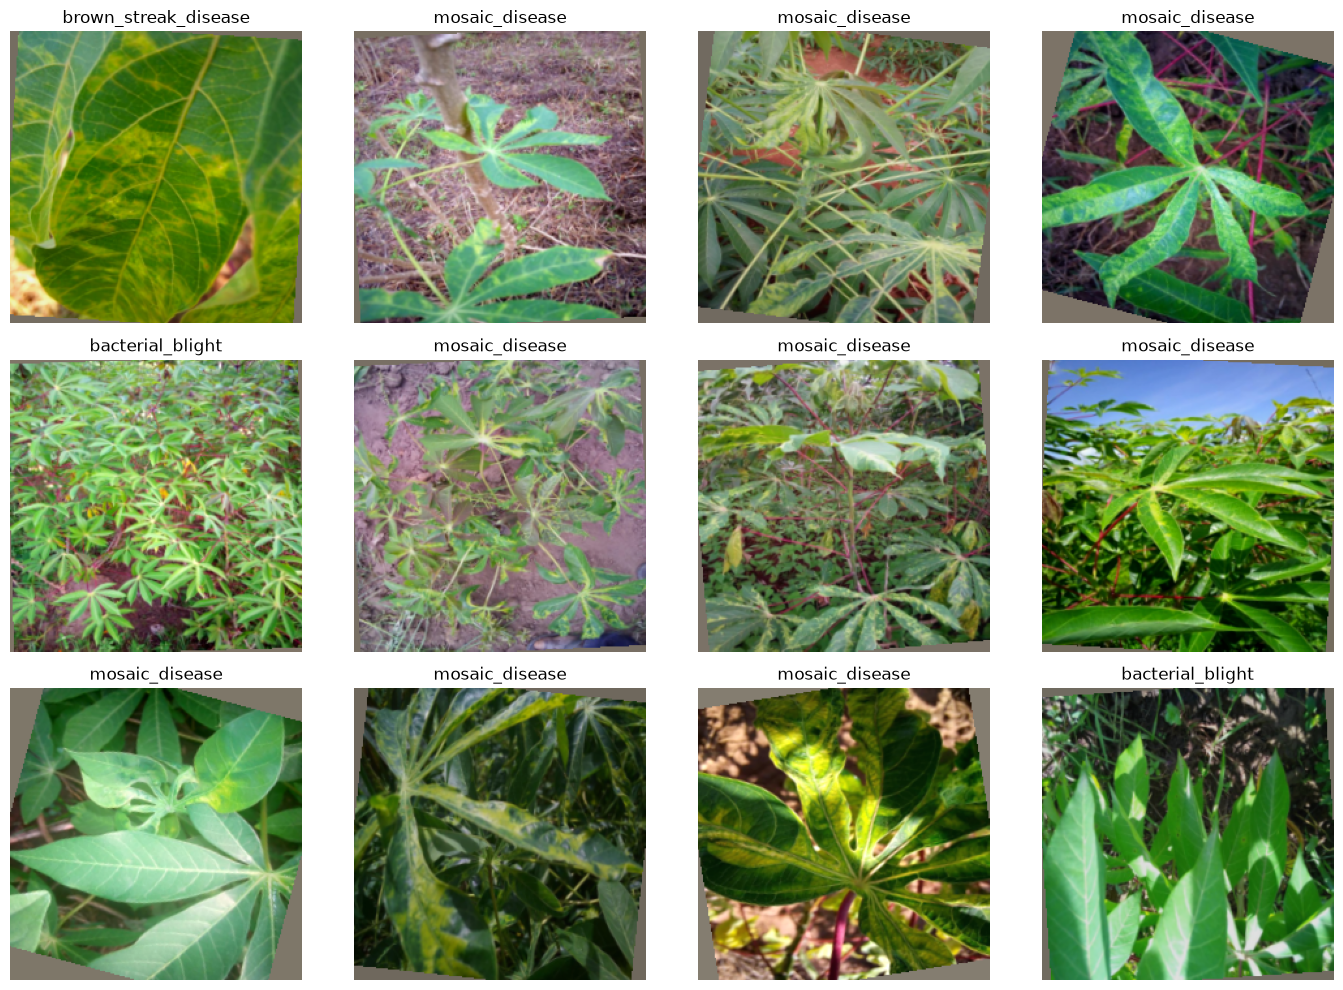

In [14]:
fig, axes = plt.subplots(
    3, 4,
    figsize=(14, 10)
)

for i, ax in enumerate(axes.flat):

    if i < len(images):

        image = denormalize(images[i])

        label = labels[i].item()

        class_name = IDX_TO_CLASS[label]

        ax.imshow(image)

        ax.set_title(class_name)

    ax.axis("off")

plt.tight_layout()

plt.savefig(
    REPORTS_DIR / "train_batch_examples.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

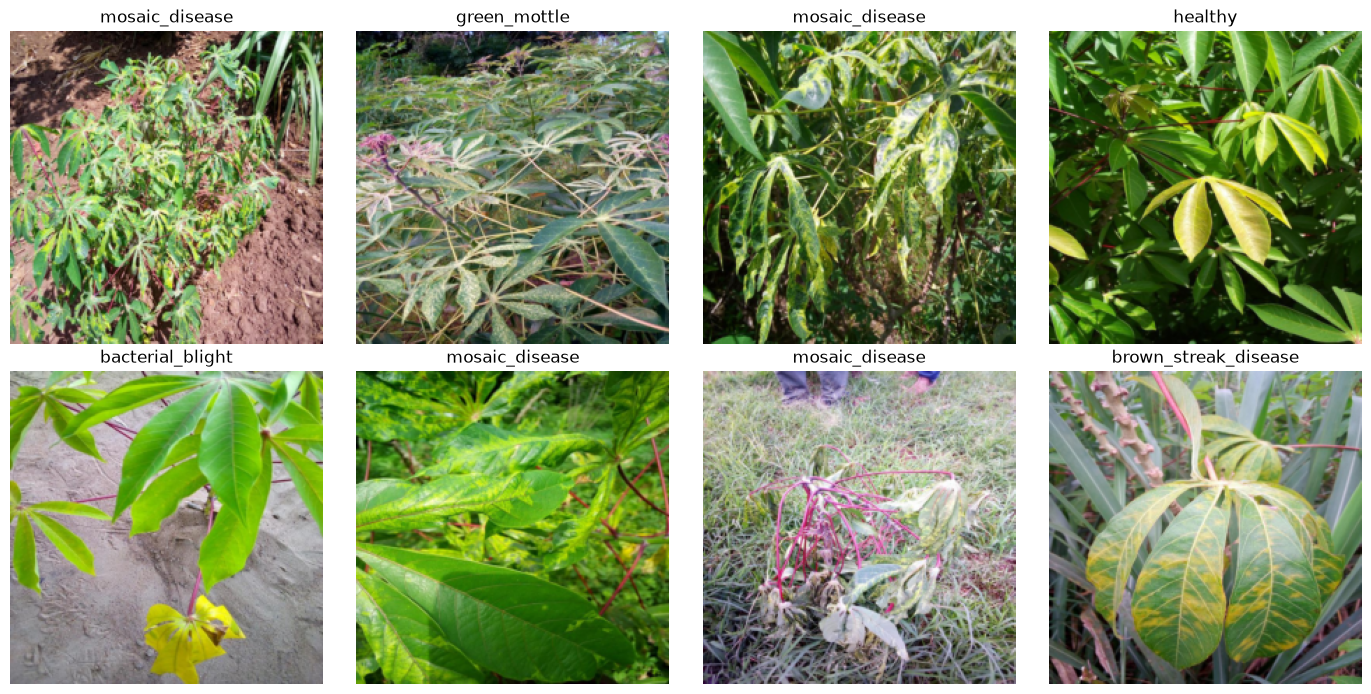

In [15]:
val_images, val_labels = next(iter(val_loader))

fig, axes = plt.subplots(
    2, 4,
    figsize=(14, 7)
)

for i, ax in enumerate(axes.flat):

    if i < len(val_images):

        image = denormalize(val_images[i])

        label = val_labels[i].item()

        class_name = IDX_TO_CLASS[label]

        ax.imshow(image)

        ax.set_title(class_name)

    ax.axis("off")

plt.tight_layout()

plt.savefig(
    REPORTS_DIR / "validation_batch_examples.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

In [16]:
expected_size = tuple(
    preprocessing_config["image_size"]
)

expected_channels = preprocessing_config[
    "num_channels"
]

for loader in [train_loader, val_loader]:

    batch_images, batch_labels = next(iter(loader))

    assert batch_images.ndim == 4

    assert tuple(batch_images.shape[1:]) == (
        expected_channels,
        *expected_size
    )

    assert batch_images.dtype == torch.float32

    assert batch_labels.dtype == torch.long

    assert len(batch_images) == len(batch_labels)

    assert batch_labels.min().item() >= 0

    assert batch_labels.max().item() < NUM_CLASSES

    assert torch.isfinite(batch_images).all()

print("Dimensiones y etiquetas correctas.")

Dimensiones y etiquetas correctas.


In [17]:
df_train = train_loader.dataset.dataframe

df_val = val_loader.dataset.dataframe

df_test = df_splits[
    df_splits["split"] == "test"
]

# Verificar rutas
train_paths = set(df_train["filepath"])

val_paths = set(df_val["filepath"])

test_paths = set(df_test["filepath"])

assert train_paths.isdisjoint(val_paths)

assert train_paths.isdisjoint(test_paths)

assert val_paths.isdisjoint(test_paths)

# Verificar hashes
train_hashes = set(df_train["sha256"])

val_hashes = set(df_val["sha256"])

test_hashes = set(df_test["sha256"])

assert train_hashes.isdisjoint(val_hashes)

assert train_hashes.isdisjoint(test_hashes)

assert val_hashes.isdisjoint(test_hashes)

print("No existe solapamiento de rutas ni hashes.")

No existe solapamiento de rutas ni hashes.


In [18]:
fold_records = []

for fold in range(1, N_SPLITS + 1):

    fold_train_loader, fold_val_loader = (
        create_fold_loaders(

            df_splits=df_splits,

            dataset_dir=DATASET_DIR,

            class_mapping=CLASS_MAPPING,

            train_transform=train_transform,

            eval_transform=eval_transform,

            fold=fold,

            batch_size=BATCH_SIZE,

            num_workers=NUM_WORKERS,

            seed=SEED

        )
    )

    train_df = fold_train_loader.dataset.dataframe

    val_df = fold_val_loader.dataset.dataframe

    assert set(train_df["filepath"]).isdisjoint(
        set(val_df["filepath"])
    )

    assert set(train_df["sha256"]).isdisjoint(
        set(val_df["sha256"])
    )

    assert train_df["split"].eq("development").all()

    assert val_df["split"].eq("development").all()

    assert train_df["fold"].ne(fold).all()

    assert val_df["fold"].eq(fold).all()

    assert len(train_df) + len(val_df) == (
        df_splits["split"].eq("development").sum()
    )

    fold_records.append({

        "fold": fold,

        "train_images": len(train_df),

        "val_images": len(val_df),

        "train_batches": len(fold_train_loader),

        "val_batches": len(fold_val_loader)

    })


df_loader_summary = pd.DataFrame(fold_records)

display(df_loader_summary)

df_loader_summary.to_csv(

    REPORTS_DIR / "dataloader_summary.csv",

    index=False,

    encoding="utf-8-sig"

)

print("Los tres folds fueron verificados.")

,fold,train_images,val_images,train_batches,val_batches
0,1,12124,6063,379,190
1,2,12125,6062,379,190
2,3,12125,6062,379,190


Los tres folds fueron verificados.


In [19]:
dataloader_config = {

    "batch_size": BATCH_SIZE,

    "num_workers": NUM_WORKERS,

    "seed": SEED,

    "shuffle": {

        "train": True,

        "validation": False,

        "test": False

    },

    "drop_last": False,

    "pin_memory": "auto_cuda",

    "label_dtype": "int64",

    "image_dtype": "float32",

    "tensor_format": "NCHW"

}

with open(

    CONFIGS_DIR / "dataloader_config.json",

    "w",

    encoding="utf-8"

) as f:

    json.dump(

        dataloader_config,

        f,

        indent=4

    )

print("Configuración del DataLoader guardada.")

Configuración del DataLoader guardada.
